# Semantic Classification

V tomto úkolu jsem se rozhodl se zaměřit na český rybníček a proto jsem místo datasetu `AG NEWS` zvolil dataset `hynky/czech_news_dataset_v2` se články z českých novinových zdrojů. Z datasetu využiju pouze sloupce `brief` (krátký popisek, podobný textu v AG News) a `category` sloupec kategorií.

### Kategorie

#### Train (1641471 řádků)

- None: 583367
- Domácí: 265352
- Sport: 179949
- Zahraniční: 174503
- Kultura: 94469
- Ekonomika: 79473
- Krimi: 58100
- Technologie: 40221
- Životní styl: 33197
- Koktejl: 24943
- Auto: 20293
- Věda: 13324
- Finance: 13162
- Cestování: 13154
- Bydlení: 12821
- Podnikání: 8704
- Komentáře: 8536
- Revue: 8498
- Byznys: 4262
- Vánoce: 1584
- Rozhovory: 1369
- Výtvarné umění: 1057
- Literatura: 938
- Kolo: 98
- Koronavirus: 89
- Podcasty: 8

#### Validation (144836 řádků)

- None: 52987
- Domácí: 29674
- Sport: 22192
- Zahraniční: 9714
- Ekonomika: 4534
- Kultura: 3387
- Koronavirus: 3226
- Byznys: 3058
- Komentáře: 2393
- Technologie: 2346
- Životní styl: 2164
- Auto: 1761
- Podnikání: 1544
- Věda: 1081
- Bydlení: 816
- Revue: 735
- Cestování: 669
- Krimi: 657
- Finance: 610
- Podcasty: 309
- Koktejl: 288
- Rozhovory: 277
- Literatura: 232
- Výtvarné umění: 150
- Vánoce: 32

#### Test (144837 řádků)

- None: 48461
- Domácí: 34416
- Sport: 21958
- Zahraniční: 11360
- Byznys: 3926
- Kultura: 3691
- Ekonomika: 3282
- Koronavirus: 2636
- Technologie: 2130
- Životní styl: 1880
- Komentáře: 1647
- Auto: 1574
- Krimi: 1379
- Věda: 1347
- Podcasty: 1036
- Revue: 690
- Cestování: 680
- Bydlení: 613
- Finance: 577
- Podnikání: 575
- Literatura: 247
- Výtvarné umění: 219
- Rozhovory: 216
- Koktejl: 207
- Kolo: 74
- Vánoce: 16

## Importy

In [1]:
from __future__ import annotations

from collections import Counter
from pathlib import Path
from typing import Any, Final, Literal, TypeAlias

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import Dataset, concatenate_datasets, load_dataset
from sentence_transformers import SentenceTransformer
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import ParameterGrid
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

sns.set_theme(style="whitegrid")


## Příprava datasetu

Český dataset obsahuje mnohem více kategorií něž `AG News`, který má pouze 4 kategorie (`World`, `Sports`, `Business`, `Sci/Tech`). Počet záznamů v každé kategorii je taky velmi nevyvážený.

### Kategorie

Zvolil jsem pouze 4 hlavní kategorie podobné `AG News`.

- `Zahraniční` -> `World`
- `Sport` -> `Sports`
- `Byznys` -> `Business`
- `Věda` + `Technologie` -> `SciTech`

### Počet záznamů

Z celkových 1,6 milionů záznamů je zvoleno 5000 trénovacích, 1000 testovacích a 1000 validačních záznamů.

Z každé kategorie je zvoleno stejný počet záznamů.


In [2]:
DATASET_NAME: Final[str] = "hynky/czech_news_dataset_v2"
RANDOM_SEED: Final[int] = 42

Label: TypeAlias = Literal["World", "Sports", "Business", "SciTech"]
LABELS: Final[list[Label]] = ["World", "Sports", "Business", "SciTech"]

SOURCE_TO_TARGET: Final[dict[str, Label]] = {
    "Zahraniční": "World",
    "Sport": "Sports",
    "Byznys": "Business",
    "Věda": "SciTech",
    "Technologie": "SciTech",
}


In [3]:
def load_split_dataset(split_name: str) -> Dataset:
    """Načte split daného datasetu a odstraní nepotřebné sloupce"""

    dataset = load_dataset(DATASET_NAME, split=split_name)
    columns_to_remove = [column for column in dataset.column_names if column not in {"brief", "category"}]
    if columns_to_remove:
        dataset = dataset.remove_columns(columns_to_remove)
    return dataset


def map_rows_to_labels(split_dataset: Dataset) -> Dataset:
    """Namapuje kategorie datasetu do AG News kategorií"""

    category_feature = split_dataset.features["category"]
    names = getattr(category_feature, "names", None)
    if names is None:
        raise TypeError("The dataset category feature does not expose class names.")

    label_lookup = {index: str(name) for index, name in enumerate(names)}

    def map_function(row: dict[str, object]) -> dict[str, str | None]:
        raw_category = row["category"]
        source_label = label_lookup.get(int(raw_category)) if raw_category is not None else None
        target_label = SOURCE_TO_TARGET.get(source_label) if source_label is not None else None
        return {
            "text": str(row["brief"]),
            "label": target_label,
        }

    return split_dataset.map(
        map_function,
        remove_columns=split_dataset.column_names,
        desc="Mapping source categories to target labels",
    )


def filter_target_labels(mapped_dataset: Dataset) -> Dataset:
    """Odstraní neznámé AG News kategorie"""

    return mapped_dataset.filter(
        lambda row: row["label"] is not None,
        desc="Filtering selected target labels",
    )


def subset_for_label(mapped_dataset: Dataset, label: Label) -> Dataset:
    """Vybere data z datasetu pro danou kategorii"""

    return mapped_dataset.filter(
        lambda row: row["label"] == label,
        desc=f"Selecting {label} rows",
    )


def sample_balanced_rows(split_name: str, rows_per_label: int, seed: int) -> pd.DataFrame:
    """Náhodný výběr dat z datasetu s vyváženým počtem záznamů v každé kategorii"""

    base_dataset = load_split_dataset(split_name)
    mapped_dataset = filter_target_labels(map_rows_to_labels(base_dataset))
    sampled_datasets: list[Dataset] = []

    for index, label in enumerate(LABELS):
        label_dataset = subset_for_label(mapped_dataset, label)
        label_count = len(label_dataset)
        if label_count < rows_per_label:
            raise ValueError(
                f"Split '{split_name}' does not contain enough rows for label '{label}': "
                f"expected at least {rows_per_label}, found {label_count}."
            )

        generator = np.random.default_rng(seed + index)
        shuffled_dataset = label_dataset.shuffle(generator=generator)
        sampled_datasets.append(shuffled_dataset.select(range(rows_per_label)))

    combined_dataset = concatenate_datasets(sampled_datasets)
    combined_dataset = combined_dataset.shuffle(generator=np.random.default_rng(seed))
    frame = combined_dataset.to_pandas()
    return frame.loc[:, ["text", "label"]]


def prepare_dataset(split_name: str, rows_per_label: int) -> pd.DataFrame:
    """Příprava datasetu. Nejprve se pokusí načíst uložená data, jinak si stáhne a vytvoří nová"""

    file_name = f"{split_name}.csv"
    file_path = Path(file_name)
    if file_path.exists():
        print(f"Using existing file: {file_name}")
        return pd.read_csv(file_path)

    print(f"Creating file: {file_name}")
    frame = sample_balanced_rows(split_name, rows_per_label, RANDOM_SEED)
    frame.to_csv(file_path, index=False)
    return frame


In [4]:
train = prepare_dataset("train", 1250)
validation = prepare_dataset("validation", 250)
test = prepare_dataset("test", 250)

X_train: pd.Series = train["text"]
y_train: pd.Series = train["label"]
X_validation: pd.Series = validation["text"]
y_validation: pd.Series = validation["label"]
X_test: pd.Series = test["text"]
y_test: pd.Series = test["label"]
X_train_validation: pd.Series = pd.concat([X_train, X_validation], ignore_index=True)
y_train_validation: pd.Series = pd.concat([y_train, y_validation], ignore_index=True)


Using existing file: train.csv
Using existing file: validation.csv
Using existing file: test.csv


## Ukázka připravených dat

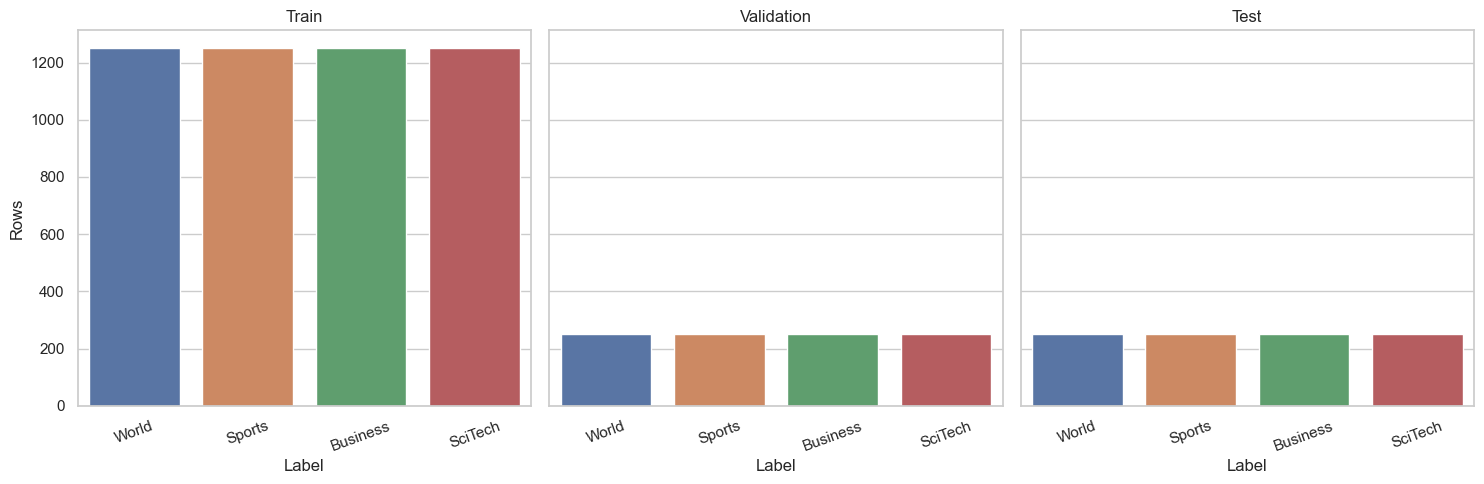

In [5]:
figure, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for axis, data, title in zip(axes, [train, validation, test], ["Train", "Validation", "Test"]):
    counts = data["label"].value_counts().reindex(LABELS, fill_value=0)
    sns.barplot(x=counts.index, y=counts.values, ax=axis, hue=counts.index, palette="deep", legend=False)
    axis.set_title(title)
    axis.set_xlabel("Label")
    axis.set_ylabel("Rows")
    axis.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [6]:
train.head()

,text,label
0,Dotykové displeje jsou fenoménem dnešní doby. ...,SciTech
1,Diskriminace na pracovištích přetrvává vcelosv...,Business
2,Už sedm Čechů přišlo o život během letošní let...,World
3,Hokejisté Motoru České Budějovice potvrdili ve...,Sports
4,Vlády v kolínské automobilce TPCA se ujímá dos...,Business


## Task 1: TF-IDF

Pro reprezentaci textu použiji `TfidfVectorizer`. Následně vyzkouším tři klasické modely pro klasifikaci textu: `MultinomialNB`, `LogisticRegression` a `LinearSVC`.

Hyperparametry budu ladit na `validation` splitu, přičemž u TF-IDF rozšířím hledání i o bohatší reprezentace textu včetně char n-gramů. Na konci vždy změřím finální přesnost na `test` splitu.

In [7]:
ModelParams: TypeAlias = dict[str, object]
ParameterGridConfig: TypeAlias = dict[str, list[object]] | list[dict[str, list[object]]]


def tune_and_refit_estimator(
    estimator: Any,
    parameter_grid: ParameterGridConfig,
    X_train_data: pd.Series | np.ndarray,
    y_train_data: pd.Series,
    X_validation_data: pd.Series | np.ndarray,
    y_validation_data: pd.Series,
    X_refit_data: pd.Series | np.ndarray,
    y_refit_data: pd.Series,
) -> tuple[ModelParams, float, Any]:
    """Najde nejlepší hyperparametry podle validation accuracy a model znovu natrénuje na train + validation."""

    best_params: ModelParams = {}
    best_validation_accuracy = float("-inf")

    for params in ParameterGrid(parameter_grid):
        candidate = clone(estimator)
        candidate.set_params(**params)
        candidate.fit(X_train_data, y_train_data)
        validation_predictions = candidate.predict(X_validation_data)
        validation_accuracy = float(accuracy_score(y_validation_data, validation_predictions))

        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            best_params = dict(params)

    best_model = clone(estimator)
    best_model.set_params(**best_params)
    best_model.fit(X_refit_data, y_refit_data)
    return best_params, best_validation_accuracy, best_model


tfidf_nb_estimator = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB()),
])
tfidf_nb_grid: ParameterGridConfig = [
    {
        "tfidf__analyzer": ["word"],
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [1, 2],
        "tfidf__max_df": [0.9, 1.0],
        "tfidf__sublinear_tf": [False, True],
        "classifier__alpha": [0.05, 0.1, 0.5, 1.0],
        "classifier__fit_prior": [True, False],
    },
    {
        "tfidf__analyzer": ["char_wb"],
        "tfidf__ngram_range": [(3, 5), (4, 6)],
        "tfidf__min_df": [1, 2],
        "tfidf__max_df": [1.0],
        "tfidf__sublinear_tf": [True],
        "classifier__alpha": [0.05, 0.1, 0.5],
        "classifier__fit_prior": [True, False],
    },
]

tfidf_lr_estimator = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
])
tfidf_lr_grid: ParameterGridConfig = [
    {
        "tfidf__analyzer": ["word"],
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [1, 2],
        "tfidf__max_df": [0.9, 1.0],
        "tfidf__sublinear_tf": [False, True],
        "classifier__C": [0.1, 0.3, 1.0, 3.0, 10.0],
        "classifier__class_weight": [None, "balanced"],
        "classifier__solver": ["lbfgs"],
    },
    {
        "tfidf__analyzer": ["char_wb"],
        "tfidf__ngram_range": [(3, 5), (4, 6)],
        "tfidf__min_df": [1, 2],
        "tfidf__max_df": [1.0],
        "tfidf__sublinear_tf": [True],
        "classifier__C": [0.1, 0.3, 1.0, 3.0],
        "classifier__class_weight": [None, "balanced"],
        "classifier__solver": ["lbfgs"],
    },
]

tfidf_svc_estimator = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LinearSVC(random_state=RANDOM_SEED)),
])
tfidf_svc_grid: ParameterGridConfig = [
    {
        "tfidf__analyzer": ["word"],
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [1, 2],
        "tfidf__max_df": [0.9, 1.0],
        "tfidf__sublinear_tf": [False, True],
        "classifier__C": [0.1, 0.3, 1.0, 3.0, 10.0],
        "classifier__class_weight": [None, "balanced"],
    },
    {
        "tfidf__analyzer": ["char_wb"],
        "tfidf__ngram_range": [(3, 5), (4, 6)],
        "tfidf__min_df": [1, 2],
        "tfidf__max_df": [1.0],
        "tfidf__sublinear_tf": [True],
        "classifier__C": [0.1, 0.3, 1.0, 3.0],
        "classifier__class_weight": [None, "balanced"],
    },
]


In [8]:
best_tfidf_nb_params, best_tfidf_nb_validation_accuracy, best_tfidf_nb_model = tune_and_refit_estimator(
    estimator=tfidf_nb_estimator,
    parameter_grid=tfidf_nb_grid,
    X_train_data=X_train,
    y_train_data=y_train,
    X_validation_data=X_validation,
    y_validation_data=y_validation,
    X_refit_data=X_train_validation,
    y_refit_data=y_train_validation,
)
tfidf_NB_predictions = best_tfidf_nb_model.predict(X_test)
tfidf_NB_accuracy = float(accuracy_score(y_test, tfidf_NB_predictions))
print(f"MultinomialNB best params: {best_tfidf_nb_params}")
print(f"MultinomialNB validation accuracy: {best_tfidf_nb_validation_accuracy:.4f}")
print(f"MultinomialNB accuracy: {tfidf_NB_accuracy:.4f}")

best_tfidf_lr_params, best_tfidf_lr_validation_accuracy, best_tfidf_lr_model = tune_and_refit_estimator(
    estimator=tfidf_lr_estimator,
    parameter_grid=tfidf_lr_grid,
    X_train_data=X_train,
    y_train_data=y_train,
    X_validation_data=X_validation,
    y_validation_data=y_validation,
    X_refit_data=X_train_validation,
    y_refit_data=y_train_validation,
)
tfidf_LR_predictions = best_tfidf_lr_model.predict(X_test)
tfidf_LR_accuracy = float(accuracy_score(y_test, tfidf_LR_predictions))
print(f"TF-IDF LogisticRegression best params: {best_tfidf_lr_params}")
print(f"TF-IDF LogisticRegression validation accuracy: {best_tfidf_lr_validation_accuracy:.4f}")
print(f"LogisticRegression accuracy: {tfidf_LR_accuracy:.4f}")

best_tfidf_svc_params, best_tfidf_svc_validation_accuracy, best_tfidf_svc_model = tune_and_refit_estimator(
    estimator=tfidf_svc_estimator,
    parameter_grid=tfidf_svc_grid,
    X_train_data=X_train,
    y_train_data=y_train,
    X_validation_data=X_validation,
    y_validation_data=y_validation,
    X_refit_data=X_train_validation,
    y_refit_data=y_train_validation,
)
tfidf_SVC_predictions = best_tfidf_svc_model.predict(X_test)
tfidf_SVC_accuracy = float(accuracy_score(y_test, tfidf_SVC_predictions))
print(f"TF-IDF LinearSVC best params: {best_tfidf_svc_params}")
print(f"TF-IDF LinearSVC validation accuracy: {best_tfidf_svc_validation_accuracy:.4f}")
print(f"LinearSVC accuracy: {tfidf_SVC_accuracy:.4f}")


MultinomialNB best params: {'classifier__alpha': 0.05, 'classifier__fit_prior': True, 'tfidf__analyzer': 'char_wb', 'tfidf__max_df': 1.0, 'tfidf__min_df': 2, 'tfidf__ngram_range': (3, 5), 'tfidf__sublinear_tf': True}
MultinomialNB validation accuracy: 0.8650
MultinomialNB accuracy: 0.8540
TF-IDF LogisticRegression best params: {'classifier__C': 3.0, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs', 'tfidf__analyzer': 'char_wb', 'tfidf__max_df': 1.0, 'tfidf__min_df': 1, 'tfidf__ngram_range': (4, 6), 'tfidf__sublinear_tf': True}
TF-IDF LogisticRegression validation accuracy: 0.8710
LogisticRegression accuracy: 0.8620
TF-IDF LinearSVC best params: {'classifier__C': 0.3, 'classifier__class_weight': None, 'tfidf__analyzer': 'char_wb', 'tfidf__max_df': 1.0, 'tfidf__min_df': 2, 'tfidf__ngram_range': (4, 6), 'tfidf__sublinear_tf': True}
TF-IDF LinearSVC validation accuracy: 0.8730
LinearSVC accuracy: 0.8640


## Baseline

Jako jednoduchý baseline pro embeddingovou část ponechám `GaussianNB`, protože jde o velmi lehký klasifikátor nad hustými vektory. Pokročilejší lineární modely a jemně doladěné embeddingy pak mohu porovnávat právě vůči tomuto základu.

## Task 2: Sémantické Embeddings

V této části použiji předtrénovaný model `Seznam/simcse-dist-mpnet-czeng-cs-en` ze `sentence-transformers`. Texty z `train`, `validation` a `test` splitu převedu na husté sémantické embeddingy a následně na nich natrénuji tři klasifikátory: `GaussianNB`, `LogisticRegression` a `LinearSVC`.

Na konci opět změřím přesnost obou modelů na `test` splitu.

In [9]:
EMBEDDING_MODEL_NAME: Final[str] = "Seznam/simcse-dist-mpnet-czeng-cs-en"
EMBEDDING_BATCH_SIZE: Final[int] = 32
EMBEDDING_MAX_SEQ_LENGTH: Final[int] = 256

embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
embedding_model.max_seq_length = EMBEDDING_MAX_SEQ_LENGTH

train_embeddings: np.ndarray = embedding_model.encode(
    X_train.tolist(),
    batch_size=EMBEDDING_BATCH_SIZE,
    convert_to_numpy=True,
    show_progress_bar=True,
)
validation_embeddings: np.ndarray = embedding_model.encode(
    X_validation.tolist(),
    batch_size=EMBEDDING_BATCH_SIZE,
    convert_to_numpy=True,
    show_progress_bar=True,
)
test_embeddings: np.ndarray = embedding_model.encode(
    X_test.tolist(),
    batch_size=EMBEDDING_BATCH_SIZE,
    convert_to_numpy=True,
    show_progress_bar=True,
)

train_validation_embeddings: np.ndarray = np.vstack([train_embeddings, validation_embeddings])


Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

In [10]:
embedding_nb_estimator = GaussianNB()
embedding_nb_grid: dict[str, list[object]] = {
    "var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7],
}
best_embedding_nb_params, best_embedding_nb_validation_accuracy, best_embedding_nb_model = tune_and_refit_estimator(
    estimator=embedding_nb_estimator,
    parameter_grid=embedding_nb_grid,
    X_train_data=train_embeddings,
    y_train_data=y_train,
    X_validation_data=validation_embeddings,
    y_validation_data=y_validation,
    X_refit_data=train_validation_embeddings,
    y_refit_data=y_train_validation,
)
embedding_NB_predictions = best_embedding_nb_model.predict(test_embeddings)
embedding_NB_accuracy = float(accuracy_score(y_test, embedding_NB_predictions))
print(f"GaussianNB best params: {best_embedding_nb_params}")
print(f"GaussianNB validation accuracy: {best_embedding_nb_validation_accuracy:.4f}")
print(f"GaussianNB accuracy: {embedding_NB_accuracy:.4f}")

embedding_lr_estimator = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_SEED)),
])
embedding_lr_grid: ParameterGridConfig = {
    "classifier__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs", "saga"],
}
best_embedding_lr_params, best_embedding_lr_validation_accuracy, best_embedding_lr_model = tune_and_refit_estimator(
    estimator=embedding_lr_estimator,
    parameter_grid=embedding_lr_grid,
    X_train_data=train_embeddings,
    y_train_data=y_train,
    X_validation_data=validation_embeddings,
    y_validation_data=y_validation,
    X_refit_data=train_validation_embeddings,
    y_refit_data=y_train_validation,
)
embedding_LR_predictions = best_embedding_lr_model.predict(test_embeddings)
embedding_LR_accuracy = float(accuracy_score(y_test, embedding_LR_predictions))
print(f"Embedding LogisticRegression best params: {best_embedding_lr_params}")
print(f"Embedding LogisticRegression validation accuracy: {best_embedding_lr_validation_accuracy:.4f}")
print(f"LogisticRegression accuracy: {embedding_LR_accuracy:.4f}")

embedding_svc_estimator = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(random_state=RANDOM_SEED)),
])
embedding_svc_grid: ParameterGridConfig = {
    "classifier__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    "classifier__class_weight": [None, "balanced"],
}
best_embedding_svc_params, best_embedding_svc_validation_accuracy, best_embedding_svc_model = tune_and_refit_estimator(
    estimator=embedding_svc_estimator,
    parameter_grid=embedding_svc_grid,
    X_train_data=train_embeddings,
    y_train_data=y_train,
    X_validation_data=validation_embeddings,
    y_validation_data=y_validation,
    X_refit_data=train_validation_embeddings,
    y_refit_data=y_train_validation,
)
embedding_SVC_predictions = best_embedding_svc_model.predict(test_embeddings)
embedding_SVC_accuracy = float(accuracy_score(y_test, embedding_SVC_predictions))
print(f"Embedding LinearSVC best params: {best_embedding_svc_params}")
print(f"Embedding LinearSVC validation accuracy: {best_embedding_svc_validation_accuracy:.4f}")
print(f"LinearSVC accuracy: {embedding_SVC_accuracy:.4f}")


GaussianNB best params: {'var_smoothing': 1e-11}
GaussianNB validation accuracy: 0.7930
GaussianNB accuracy: 0.8100
Embedding LogisticRegression best params: {'classifier__C': 0.01, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Embedding LogisticRegression validation accuracy: 0.8600
LogisticRegression accuracy: 0.8660
Embedding LinearSVC best params: {'classifier__C': 0.03, 'classifier__class_weight': None}
Embedding LinearSVC validation accuracy: 0.8610
LinearSVC accuracy: 0.8560


## Task 3: Confusion Matrix

V této části zobrazím konfuzní matice pro všechny natrénované modely. Díky tomu je vidět, ve kterých kategoriích jednotlivé klasifikátory nejčastěji chybují.

In [11]:
model_predictions: dict[str, np.ndarray] = {
    "TF-IDF MultinomialNB": np.asarray(tfidf_NB_predictions),
    "TF-IDF LogisticRegression": np.asarray(tfidf_LR_predictions),
    "TF-IDF LinearSVC": np.asarray(tfidf_SVC_predictions),
    "Embeddings GaussianNB": np.asarray(embedding_NB_predictions),
    "Embeddings LogisticRegression": np.asarray(embedding_LR_predictions),
    "Embeddings LinearSVC": np.asarray(embedding_SVC_predictions),
}


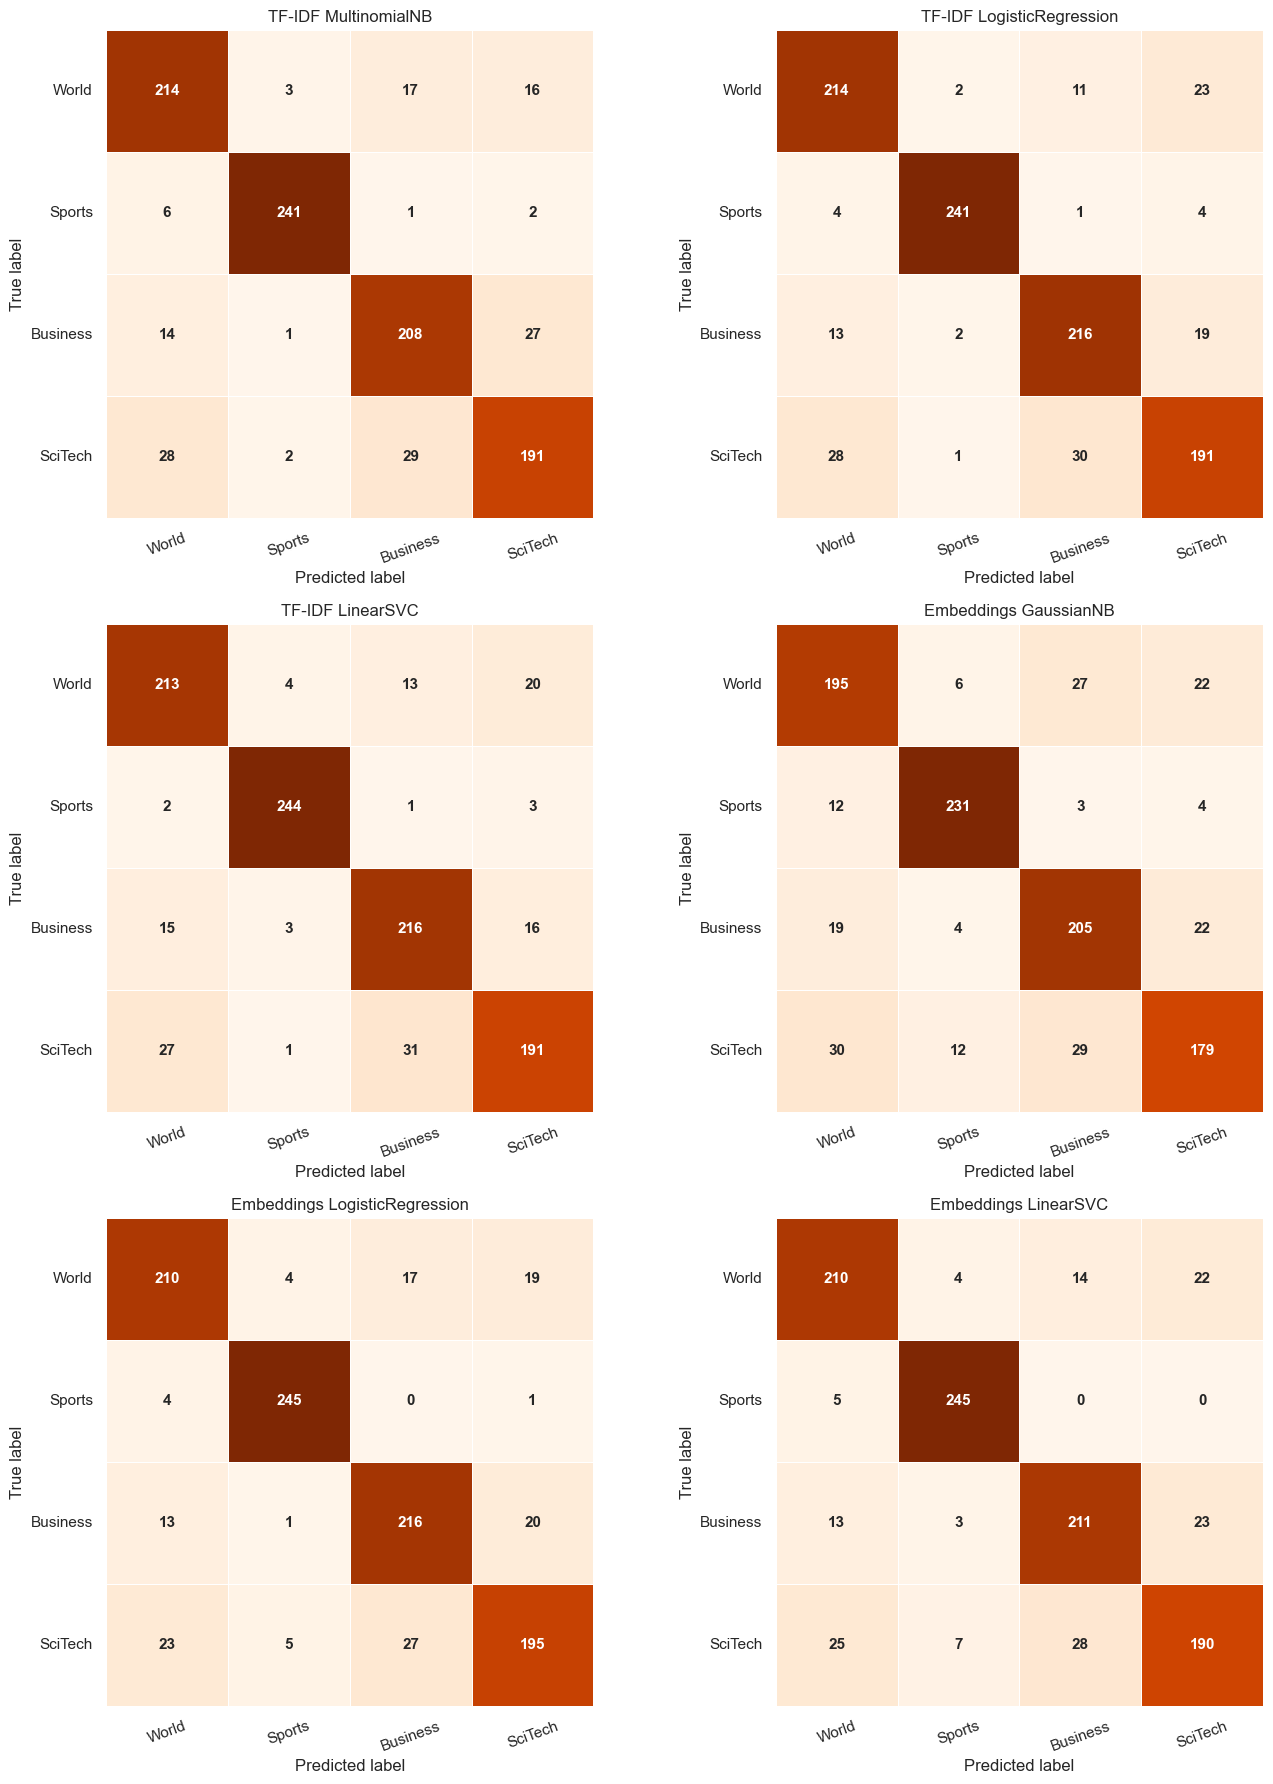

In [12]:
figure, axes = plt.subplots(3, 2, figsize=(14, 18))

for axis, (model_name, predictions) in zip(axes.flat, model_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=LABELS)
    matrix_df = pd.DataFrame(matrix, index=LABELS, columns=LABELS)
    sns.heatmap(
        matrix_df,
        annot=True,
        fmt="d",
        cmap="Oranges",
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        square=True,
        ax=axis,
        annot_kws={"size": 11, "weight": "bold"},
    )
    axis.set_title(model_name)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")
    axis.tick_params(axis="x", rotation=20)
    axis.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


## Task 4: FAISS

V této části použiji `faiss-cpu` pro klasifikaci pomocí k-nejbližších sousedů nad sémantickými embeddingy. Nejprve vytvořím FAISS index z trénovacích vektorů a následně pro každý text z `test` splitu vyhledám `k = 5` nejbližších sousedů.

Výsledná kategorie bude určena většinovým hlasováním nalezených sousedů. Pokud nastane remíza, vyberu kategorii nejbližšího souseda z remizujících tříd.

In [13]:
FAISS_K: Final[int] = 5


def normalize_for_faiss(embeddings: np.ndarray) -> np.ndarray:
    """Převede embeddingy na float32 a normalizuje je pro cosine-like vyhledávání"""

    normalized_embeddings = np.asarray(embeddings, dtype=np.float32).copy()
    faiss.normalize_L2(normalized_embeddings)
    return normalized_embeddings


def predict_faiss_label(indices: np.ndarray, distances: np.ndarray, train_labels: pd.Series) -> Label:
    """Vrátí label podle majority vote, při remíze rozhodne nejbližší soused z remizujících labelů"""

    neighbor_labels = [str(train_labels.iloc[int(index)]) for index in indices]
    label_counts = Counter(neighbor_labels)
    highest_count = max(label_counts.values())
    tied_labels = {label for label, count in label_counts.items() if count == highest_count}

    for index, distance in zip(indices, distances):
        candidate_label = str(train_labels.iloc[int(index)])
        if candidate_label in tied_labels:
            return candidate_label  # type: ignore[return-value]

    raise ValueError("Unable to resolve FAISS prediction from nearest neighbors.")


In [14]:
train_embeddings_faiss = normalize_for_faiss(train_embeddings)
test_embeddings_faiss = normalize_for_faiss(test_embeddings)

faiss_index = faiss.IndexFlatIP(train_embeddings_faiss.shape[1])
faiss_index.add(train_embeddings_faiss)

faiss_distances, faiss_indices = faiss_index.search(test_embeddings_faiss, FAISS_K)

faiss_predictions: list[Label] = [
    predict_faiss_label(indices, distances, y_train)
    for indices, distances in zip(faiss_indices, faiss_distances)
]

faiss_accuracy = float(accuracy_score(y_test, faiss_predictions))
print(f"FAISS k-NN accuracy: {faiss_accuracy:.4f}")


FAISS k-NN accuracy: 0.8090
